# Notebook 01: EDA and dataset cleaning

**Project:** SkinX — AI-assisted early screening of skin cancer in people with albinism in Rwanda

This notebook checks and prepares PAD-UFES-20 and MILK10k for the later model experiments. It covers:

1. Checking the Google Drive folders and the downloaded PAD-UFES-20 files (Mendeley DOI: `10.17632/zr7vgbcyr2.1`).
2. Reviewing the metadata, patient and lesion IDs, diagnosis counts, and biopsy confirmation.
3. Checking whether Fitzpatrick skin types I–II can be used as the conventional light-skin baseline.
4. Finding missing or damaged images, exact duplicates, and unusual image dimensions.
5. Reviewing MILK10k clinical close-ups and selecting suitable `TARGET` and `NON_TARGET` images.
6. Saving clean CSV manifests and an exclusion log. The raw images are left unchanged.

### Dataset scope and limitations

For the conventional baseline, we use lesion photographs that appear to show lighter skin. The aim is to study how a screening model trained on these images performs when it is later tested on images of people with albinism.

The two datasets use different skin measures:

- **PAD-UFES-20:** Fitzpatrick skin types I–II.
- **MILK10k:** visible skin-tone groups 4–5, at the lighter end of its scale.

These measures are not interchangeable. Fitzpatrick describes how skin responds to sunlight, while MILK10k records visible skin tone. We therefore refer to the combined data as an **ordinary light-appearing skin dataset**, not a uniform Fitzpatrick I–II dataset.

Neither dataset reliably records whether a person has albinism, so that cannot be confirmed for every image.

**Grouping:** PAD-UFES-20 has patient and lesion IDs, so its data can be split by patient. MILK10k has lesion IDs but no reliable patient IDs. Images of the same lesion can be kept together, but patient-level independence cannot be guaranteed for MILK10k.

**Labels:** `TARGET` includes BCC, SCC, melanoma and actinic keratosis. `NON_TARGET` contains selected non-cancerous lesions. These labels are for research screening, not clinical diagnosis.

These limits need to be kept in mind when splitting the data and interpreting the results.

In [1]:
import os
import sys
import json
import hashlib
import zipfile
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
from tqdm.notebook import tqdm

# Set the plot style.
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

# Set the random seed so sampling can be repeated.
SEED = 42
np.random.seed(SEED)

# Mount Google Drive.
from google.colab import drive
drive.mount('/content/drive')

# Record the environment details for this run.
print(f"Execution Timestamp: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python Version:      {sys.version.split()[0]}")
print(f"Pandas Version:      {pd.__version__}")
print(f"NumPy Version:       {np.__version__}")

Mounted at /content/drive
Execution Timestamp: 2026-10-19 09:26:16
Python Version:      3.13.16
Pandas Version:      2.2.3
NumPy Version:       2.1.3


In [2]:
# ==============================================================================
# Set the project paths
# ==============================================================================
PROJECT_ROOT = Path("/content/drive/MyDrive/SkinX")

RAW_PAD_DIR = PROJECT_ROOT / "data" / "raw_data" / "pad_ufes_20"
RAW_SCIN_DIR = PROJECT_ROOT / "data" / "raw" / "scin"
MANIFEST_DIR = PROJECT_ROOT / "data" / "manifests"
REPORT_DIR = PROJECT_ROOT / "reports" / "01_eda"

# Create output folders without changing the raw data.
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"PAD-UFES-20 Raw Path Exists: {RAW_PAD_DIR.exists()}")

# Check the extracted PAD-UFES-20 files.
if RAW_PAD_DIR.exists():
    print("\nContents of PAD-UFES-20 raw directory:")
    for item in sorted(RAW_PAD_DIR.iterdir()):
        kind = "[DIR] " if item.is_dir() else "[FILE]"
        print(f"  {kind} {item.name}")
else:
    print("\nWARNING: RAW_PAD_DIR not found! Please check the path above.")

Project Root: /content/drive/MyDrive/SkinX
PAD-UFES-20 Raw Path Exists: True

Contents of PAD-UFES-20 raw directory:
  [DIR]  images
  [FILE] metadata.csv


In [3]:
# 1. Load metadata.csv.
metadata_path = RAW_PAD_DIR / "metadata.csv"
assert metadata_path.exists(), f"Could not find {metadata_path}. Check folder structure."

df_pad_raw = pd.read_csv(metadata_path)
print(f"Loaded metadata.csv: {df_pad_raw.shape[0]} rows, {df_pad_raw.shape[1]} columns.")

# 2. Find PAD-UFES-20 images, including files still inside ZIP archives.
image_extensions = {".png", ".jpg", ".jpeg"}
image_files = [
    path for path in RAW_PAD_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

# The download may include several image ZIP files.
# Extract them to a separate folder so the raw files stay unchanged.
missing_ids = set(df_pad_raw["img_id"]) - {path.name for path in image_files}
archives = sorted(path for path in RAW_PAD_DIR.rglob("*.zip") if path.is_file())
if missing_ids and archives:
    extracted_dir = PROJECT_ROOT / "data" / "extracted" / "pad_ufes_20"
    for archive in archives:
        destination = extracted_dir / archive.stem
        complete_marker = destination / ".extraction_complete"
        if not complete_marker.exists():
            destination.mkdir(parents=True, exist_ok=True)
            print(f"Extracting {archive.name} (this may take a while on Drive)...")
            with zipfile.ZipFile(archive) as zipped:
                zipped.extractall(destination)
            complete_marker.touch()
    image_files.extend(
        path for path in extracted_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )

# Match each img_id to an image path and keep duplicate filenames visible for review.
image_path_map = {}
for file_path in image_files:
    if file_path.name in image_path_map:
        raise ValueError(f"Duplicate image filename found: {file_path.name}. Check the image folders.")
    image_path_map[file_path.name] = str(file_path)

print(f"Total image files indexed on disk: {len(image_path_map)}")
if not image_path_map:
    available = sorted({path.suffix.lower() for path in RAW_PAD_DIR.rglob("*") if path.is_file()})
    raise FileNotFoundError(
        f"No image files were found in {RAW_PAD_DIR}. File extensions present: {available}. "
        "Check whether the official image archives were downloaded and extracted."
    )

# 3. Add the image paths to the metadata.
df_pad = df_pad_raw.copy()
df_pad["filepath"] = df_pad["img_id"].map(image_path_map)
df_pad["file_exists"] = df_pad["filepath"].notna()

print(f"Metadata rows matched to an image file: {df_pad['file_exists'].sum()} / {len(df_pad)}")
if not df_pad["file_exists"].any():
    raise FileNotFoundError("No metadata image IDs matched the files. Check archive contents and img_id names.")
if not df_pad["file_exists"].all():
    print("Example unmatched image IDs:", df_pad.loc[~df_pad["file_exists"], "img_id"].head(5).tolist())

# Check the columns and first three rows.
display(df_pad.head(3))
print("\nColumn Data Types & Missing Values:")
display(pd.DataFrame({
    "dtype": df_pad.dtypes,
    "missing_count": df_pad.isna().sum(),
    "missing_pct": (df_pad.isna().sum() / len(df_pad) * 100).round(2)
}))

Loaded metadata.csv: 2298 rows, 26 columns.
Total image files indexed on disk: 2298
Metadata rows matched to an image file: 2298 / 2298


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed,filepath,file_exists
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,False,False,False,False,False,False,PAT_1516_1765_530.png,False,/content/drive/MyDrive/SkinX/data/extracted/pa...,True
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,True,True,False,True,True,True,PAT_46_881_939.png,True,/content/drive/MyDrive/SkinX/data/extracted/pa...,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,True,False,False,False,False,False,PAT_1545_1867_547.png,False,/content/drive/MyDrive/SkinX/data/extracted/pa...,True



Column Data Types & Missing Values:


,dtype,missing_count,missing_pct
patient_id,object,0,0.00
lesion_id,int64,0,0.00
smoke,object,804,34.99
drink,object,804,34.99
background_father,object,818,35.60
background_mother,object,822,35.77
age,int64,0,0.00
pesticide,object,804,34.99
gender,object,804,34.99
skin_cancer_history,object,804,34.99


In [4]:
# Map the source diagnoses to the SkinX labels.
TARGET_DIAGNOSES = {"BCC", "SCC", "MEL", "ACK"}
NON_TARGET_DIAGNOSES = {"NEV", "SEK"}

def map_binary_label(diag):
    if diag in TARGET_DIAGNOSES:
        return "TARGET"
    elif diag in NON_TARGET_DIAGNOSES:
        return "NON_TARGET"
    return "UNKNOWN"

df_pad["label_group"] = df_pad["diagnostic"].apply(map_binary_label)

# Count images, lesions and patients.
n_images = len(df_pad)
n_lesions = df_pad["lesion_id"].nunique()
n_patients = df_pad["patient_id"].nunique()

print("=== HIERARCHY SUMMARY (FULL PAD-UFES-20) ===")
print(f"Total Images (img_id):      {n_images}")
print(f"Unique Lesions (lesion_id): {n_lesions} (avg {n_images/n_lesions:.2f} images/lesion)")
print(f"Unique Patients (patient_id): {n_patients} (avg {n_lesions/n_patients:.2f} lesions/patient)")

# Check whether any patient has both TARGET and NON_TARGET lesions.
patient_group_counts = df_pad.groupby("patient_id")["label_group"].nunique()
multi_class_patients = (patient_group_counts > 1).sum()
print(f"Patients with both TARGET and NON_TARGET lesions: {multi_class_patients}")

# Summarize images, lesions, patients and biopsy confirmation by diagnosis.
diag_summary = df_pad.groupby(["label_group", "diagnostic"]).agg(
    images=("img_id", "count"),
    unique_lesions=("lesion_id", "nunique"),
    unique_patients=("patient_id", "nunique"),
    biopsied_images=("biopsed", lambda x: (x == True).sum()),
).reset_index()

diag_summary["biopsy_pct"] = (diag_summary["biopsied_images"] / diag_summary["images"] * 100).round(1)
diag_summary = diag_summary.sort_values(by=["label_group", "images"], ascending=[False, False])

print("\n=== DIAGNOSIS & BIOPSY DISTRIBUTION (ALL SKIN TYPES) ===")
display(diag_summary)

=== HIERARCHY SUMMARY (FULL PAD-UFES-20) ===
Total Images (img_id):      2298
Unique Lesions (lesion_id): 1641 (avg 1.40 images/lesion)
Unique Patients (patient_id): 1373 (avg 1.20 lesions/patient)
Patients with both TARGET and NON_TARGET lesions: 61

=== DIAGNOSIS & BIOPSY DISTRIBUTION (ALL SKIN TYPES) ===


,label_group,diagnostic,images,unique_lesions,unique_patients,biopsied_images,biopsy_pct
3,TARGET,BCC,845,652,513,845,100.0
2,TARGET,ACK,730,621,525,178,24.4
5,TARGET,SCC,192,145,133,192,100.0
4,TARGET,MEL,52,36,36,52,100.0
0,NON_TARGET,NEV,244,215,185,60,24.6
1,NON_TARGET,SEK,235,198,176,15,6.4


In [5]:
# The source metadata spells this column "fitspatrick".
fst_col = "fitspatrick" if "fitspatrick" in df_pad.columns else "fitzpatrick"

print(f"=== FITZPATRICK SKIN TYPE ('{fst_col}') DISTRIBUTION ===")
fst_counts = df_pad[fst_col].value_counts(dropna=False).reset_index()
fst_counts.columns = ["Fitzpatrick_Type", "Image_Count"]
fst_counts["Percentage"] = (fst_counts["Image_Count"] / len(df_pad) * 100).round(2)
display(fst_counts)

# Compare diagnosis counts across Fitzpatrick types.
print("\n=== IMAGE COUNT: FITZPATRICK TYPE vs. DIAGNOSIS ===")
fst_diag_img = pd.crosstab(
    df_pad[fst_col].fillna("Missing"),
    df_pad["diagnostic"],
    margins=True
)
display(fst_diag_img)

# Keep Fitzpatrick types I and II for the baseline.
df_fst_1_2 = df_pad[df_pad[fst_col].isin([1, 2])].copy()

fst12_summary = df_fst_1_2.groupby(["label_group", "diagnostic"]).agg(
    fst12_images=("img_id", "count"),
    fst12_lesions=("lesion_id", "nunique"),
    fst12_patients=("patient_id", "nunique"),
    fst12_biopsied=("biopsed", lambda x: (x == True).sum())
).reset_index()

print("\n=== FITZPATRICK I–II SUBSET BREAKDOWN (IMAGES, LESIONS, PATIENTS) ===")
display(fst12_summary)

print("\n=== BINARY CLASS TOTALS IN FST I–II SUBSET ===")
display(df_fst_1_2.groupby("label_group").agg(
    total_images=("img_id", "count"),
    unique_lesions=("lesion_id", "nunique"),
    unique_patients=("patient_id", "nunique")
))

=== FITZPATRICK SKIN TYPE ('fitspatrick') DISTRIBUTION ===


,Fitzpatrick_Type,Image_Count,Percentage
0,2.0,876,38.12
1,NaN,804,34.99
2,3.0,392,17.06
3,1.0,153,6.66
4,4.0,62,2.70
5,5.0,10,0.44
6,6.0,1,0.04



=== IMAGE COUNT: FITZPATRICK TYPE vs. DIAGNOSIS ===


diagnostic,ACK,BCC,MEL,NEV,SCC,SEK,All
fitspatrick,,,,,,,
1.0,25,101,3,4,16,4,153
2.0,156,502,35,34,126,23,876
3.0,89,217,10,24,45,7,392
4.0,10,22,4,12,3,11,62
5.0,3,3,0,1,2,1,10
6.0,0,0,0,0,0,1,1
Missing,447,0,0,169,0,188,804
All,730,845,52,244,192,235,2298



=== FITZPATRICK I–II SUBSET BREAKDOWN (IMAGES, LESIONS, PATIENTS) ===


,label_group,diagnostic,fst12_images,fst12_lesions,fst12_patients,fst12_biopsied
0,NON_TARGET,NEV,38,30,28,31
1,NON_TARGET,SEK,27,23,20,8
2,TARGET,ACK,181,162,123,111
3,TARGET,BCC,603,471,367,603
4,TARGET,MEL,38,26,26,38
5,TARGET,SCC,142,107,97,142



=== BINARY CLASS TOTALS IN FST I–II SUBSET ===


,total_images,unique_lesions,unique_patients
label_group,,,
NON_TARGET,65,52,48
TARGET,964,757,515


In [6]:
integrity_records = []

print("Verifying image integrity, dimensions, and MD5 hashes across all rows...")
for idx, row in tqdm(df_pad.iterrows(), total=len(df_pad)):
    img_id = row["img_id"]
    fpath = row["filepath"]

    if pd.isna(fpath) or not os.path.exists(fpath):
        integrity_records.append({
            "img_id": img_id,
            "is_valid": False,
            "error_reason": "MISSING_FILE",
            "width": np.nan,
            "height": np.nan,
            "mode": None,
            "md5_hash": None
        })
        continue

    try:
        # Calculate MD5 hashes to find exact file duplicates.
        with open(fpath, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        # Load each image to detect truncated or corrupted files.
        with Image.open(fpath) as img:
            img.load()
            width, height = img.size
            mode = img.mode

        integrity_records.append({
            "img_id": img_id,
            "is_valid": True,
            "error_reason": None,
            "width": width,
            "height": height,
            "mode": mode,
            "md5_hash": file_hash
        })
    except (UnidentifiedImageError, OSError) as e:
        integrity_records.append({
            "img_id": img_id,
            "is_valid": False,
            "error_reason": f"CORRUPTED: {type(e).__name__}",
            "width": np.nan,
            "height": np.nan,
            "mode": None,
            "md5_hash": None
        })

df_integrity = pd.DataFrame(integrity_records)
# Remove previous integrity columns before adding them again.
df_pad = df_pad.drop(columns=df_integrity.columns.drop("img_id"), errors="ignore")
df_pad = df_pad.merge(df_integrity, on="img_id", how="left")

# Summarize the integrity checks.
n_invalid = (~df_pad["is_valid"]).sum()
valid_hashes = df_pad[df_pad["is_valid"]]["md5_hash"]
n_exact_dups = valid_hashes.duplicated(keep=False).sum()

print(f"\nIntegrity Check Complete:")
print(f"  - Valid readable images: {df_pad['is_valid'].sum()} / {len(df_pad)}")
print(f"  - Missing or corrupted:  {n_invalid}")
print(f"  - Images sharing an identical MD5 hash: {n_exact_dups}")

if n_exact_dups > 0:
    print("\nInspecting rows with identical MD5 hashes:")
    dup_df = df_pad[df_pad["md5_hash"].isin(valid_hashes[valid_hashes.duplicated()])]
    display(dup_df[["img_id", "patient_id", "lesion_id", "diagnostic", "md5_hash"]].sort_values("md5_hash"))

print("\nImage Dimension Summary (Width & Height in Pixels):")
display(df_pad[["width", "height"]].describe().round(1))

Verifying image integrity, dimensions, and MD5 hashes across all rows...


  0%|          | 0/2298 [00:00<?, ?it/s]


Integrity Check Complete:
  - Valid readable images: 2298 / 2298
  - Missing or corrupted:  0
  - Images sharing an identical MD5 hash: 30

Inspecting rows with identical MD5 hashes:


,img_id,patient_id,lesion_id,diagnostic,md5_hash
1924,PAT_419_833_148.png,PAT_419,833,SCC,08b2ef2acb959c289513972f44d3048c
1087,PAT_419_2767_323.png,PAT_419,2767,ACK,08b2ef2acb959c289513972f44d3048c
1632,PAT_311_667_416.png,PAT_311,667,BCC,0be5da1ded6ea8636bb9ca8f6aea5c06
726,PAT_311_666_191.png,PAT_311,666,SCC,0be5da1ded6ea8636bb9ca8f6aea5c06
1498,PAT_570_1084_939.png,PAT_570,1084,SCC,115ea17aa99c8b8744bc15154dd7414e
677,PAT_570_1085_429.png,PAT_570,1085,BCC,115ea17aa99c8b8744bc15154dd7414e
73,PAT_701_4056_457.png,PAT_701,4056,SEK,11c96c105fb8f0df4a6d3c68c5b428c7
1357,PAT_701_1321_156.png,PAT_701,1321,SEK,11c96c105fb8f0df4a6d3c68c5b428c7
18,PAT_759_1538_566.png,PAT_759,1538,BCC,33df75c500433d977b0c5da95abfeb6c
888,PAT_759_1433_914.png,PAT_759,1433,NEV,33df75c500433d977b0c5da95abfeb6c



Image Dimension Summary (Width & Height in Pixels):


,width,height
count,2298.0,2298.0
mean,933.7,933.6
std,534.6,534.7
min,147.0,147.0
25%,528.0,527.2
50%,779.5,779.5
75%,1219.2,1218.8
max,3474.0,3476.0


=== PAD-UFES-20 EXCLUSION SUMMARY (INTEGRITY & DUPLICATES) ===
                                      Row_Count
exclusion_reason                               
None                                       2271
DUPLICATE_HASH_CONFLICTING_DIAGNOSIS         24
DUPLICATE_HASH_SAME_DIAGNOSIS                 3


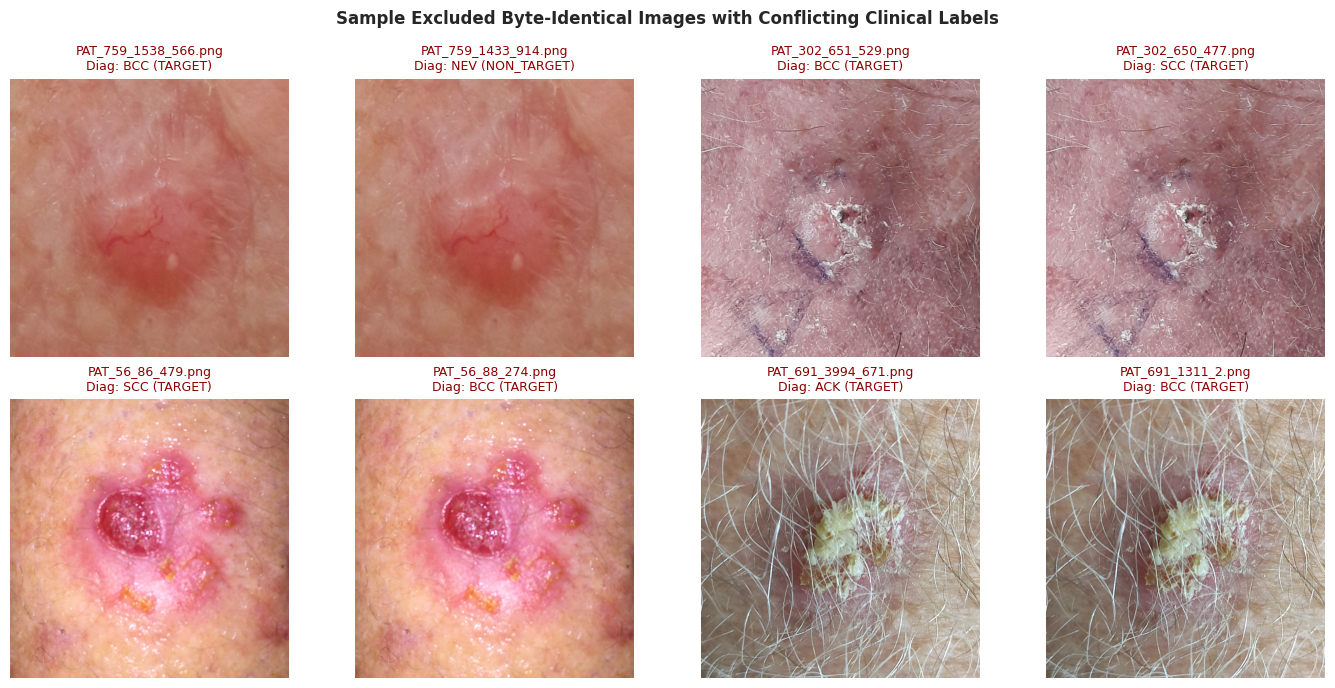

In [7]:
# Add columns to record why images are excluded.
df_pad["exclude"] = False
df_pad["exclusion_reason"] = None

# 1. Flag missing or corrupted files; keep this check even if none are found.
invalid_mask = ~df_pad["is_valid"]
df_pad.loc[invalid_mask, "exclude"] = True
df_pad.loc[invalid_mask, "exclusion_reason"] = df_pad.loc[invalid_mask, "error_reason"]

# 2. Handle exact duplicates in a consistent way.
valid_df = df_pad[df_pad["is_valid"]]
dup_hashes = valid_df[valid_df["md5_hash"].duplicated(keep=False)]["md5_hash"].unique()

for h in dup_hashes:
    group = df_pad[df_pad["md5_hash"] == h].sort_values("img_id")
    unique_diags = group["diagnostic"].nunique()

    if unique_diags > 1:
        # Exclude both copies when the same image has conflicting labels.
        df_pad.loc[group.index, "exclude"] = True
        df_pad.loc[group.index, "exclusion_reason"] = "DUPLICATE_HASH_CONFLICTING_DIAGNOSIS"
    else:
        # If the label and patient match, keep one copy and mark the duplicate for exclusion.
        redundant_idx = group.index[1:]
        df_pad.loc[redundant_idx, "exclude"] = True
        df_pad.loc[redundant_idx, "exclusion_reason"] = "DUPLICATE_HASH_SAME_DIAGNOSIS"

# Summarize the exclusions recorded so far.
print("=== PAD-UFES-20 EXCLUSION SUMMARY (INTEGRITY & DUPLICATES) ===")
print(df_pad["exclusion_reason"].value_counts(dropna=False).rename("Row_Count").to_frame())

# Review a few conflicting duplicate pairs to confirm that the files match.
conflict_hashes = df_pad[df_pad["exclusion_reason"] == "DUPLICATE_HASH_CONFLICTING_DIAGNOSIS"]["md5_hash"].unique()
if len(conflict_hashes) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()
    for i, h in enumerate(conflict_hashes[:4]):
        pair = df_pad[df_pad["md5_hash"] == h]
        for j, (_, row) in enumerate(pair.iloc[:2].iterrows()):
            ax = axes[i * 2 + j]
            with Image.open(row["filepath"]) as im:
                ax.imshow(im)
            ax.set_title(
                f"{row['img_id']}\nDiag: {row['diagnostic']} ({row['label_group']})",
                fontsize=9, color="darkred"
            )
            ax.axis("off")
    plt.suptitle("Sample Excluded Byte-Identical Images with Conflicting Clinical Labels", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(REPORT_DIR / "pad_ufes_conflicting_duplicates.png", dpi=150)
    plt.show()

Computing brightness and blur (Laplacian sharpness) metrics...


  0%|          | 0/2298 [00:00<?, ?it/s]


=== IMAGE QUALITY & DIMENSION METRICS (PAD-UFES-20) ===


,width,height,min_dim,aspect_ratio,mean_brightness,sharpness_laplacian
count,2298.00,2298.00,2298.00,2298.00,2298.00,2298.00
mean,933.68,933.61,933.41,1.00,142.38,657.25
std,534.60,534.67,534.71,0.01,22.35,1066.67
min,147.00,147.00,147.00,0.89,67.21,5.29
25%,528.00,527.25,527.25,1.00,127.71,111.45
50%,779.50,779.50,779.50,1.00,142.19,274.22
75%,1219.25,1218.75,1218.50,1.00,156.99,706.53
max,3474.00,3476.00,3474.00,1.16,219.47,11275.77


Images with extreme dimensions/aspect ratio: 0
Images with extreme under/over-exposure:     0


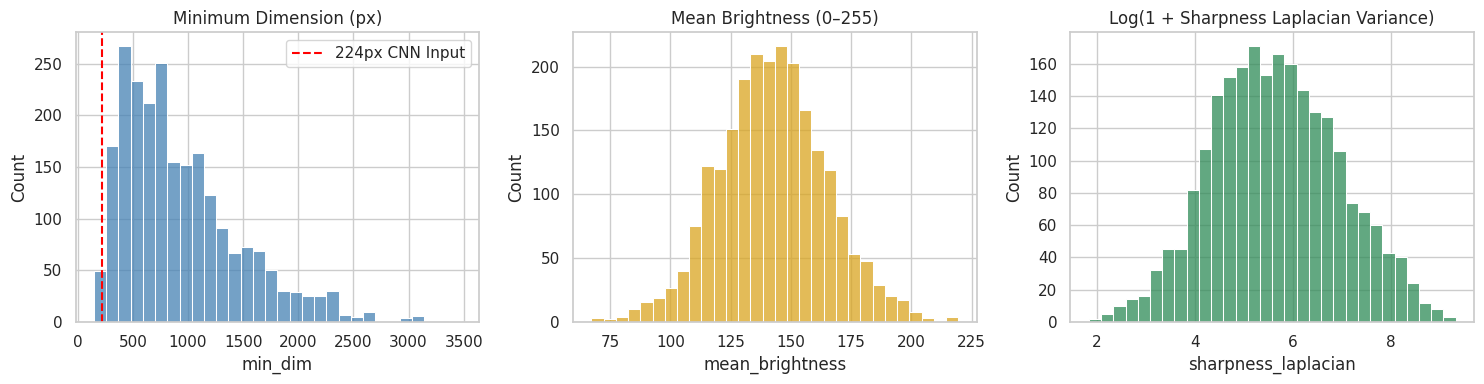

In [8]:
import cv2

# Calculate aspect ratio and basic image-quality measures for valid files.
df_pad["aspect_ratio"] = (df_pad["width"] / df_pad["height"]).round(3)
df_pad["min_dim"] = df_pad[["width", "height"]].min(axis=1)

brightness_list = []
sharpness_list = []

print("Computing brightness and blur (Laplacian sharpness) metrics...")
for idx, row in tqdm(df_pad.iterrows(), total=len(df_pad)):
    if not row["is_valid"]:
        brightness_list.append(np.nan)
        sharpness_list.append(np.nan)
        continue
    # Read the image as grayscale with PIL and NumPy.
    with Image.open(row["filepath"]) as im:
        gray = np.array(im.convert("L"), dtype=np.float32)
    brightness_list.append(float(gray.mean()))
    # Resize to 256 × 256 before measuring blur so image size has less effect.
    gray_resized = cv2.resize(gray, (256, 256))
    sharpness_list.append(float(cv2.Laplacian(gray_resized, cv2.CV_32F).var()))

df_pad["mean_brightness"] = np.round(brightness_list, 2)
df_pad["sharpness_laplacian"] = np.round(sharpness_list, 2)

print("\n=== IMAGE QUALITY & DIMENSION METRICS (PAD-UFES-20) ===")
display(df_pad[["width", "height", "min_dim", "aspect_ratio", "mean_brightness", "sharpness_laplacian"]].describe().round(2))

# Flag unusual dimensions, aspect ratios, brightness or darkness.
extreme_dim = (df_pad["min_dim"] < 128) | (df_pad["aspect_ratio"] < 0.5) | (df_pad["aspect_ratio"] > 2.0)
extreme_exp = (df_pad["mean_brightness"] < 15) | (df_pad["mean_brightness"] > 245)

print(f"Images with extreme dimensions/aspect ratio: {extreme_dim.sum()}")
print(f"Images with extreme under/over-exposure:     {extreme_exp.sum()}")

# Plot the image-quality distributions.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_pad["min_dim"], bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Minimum Dimension (px)")
axes[0].axvline(224, color="red", linestyle="--", label="224px CNN Input")
axes[0].legend()

sns.histplot(df_pad["mean_brightness"], bins=30, ax=axes[1], color="goldenrod")
axes[1].set_title("Mean Brightness (0–255)")

sns.histplot(np.log1p(df_pad["sharpness_laplacian"]), bins=30, ax=axes[2], color="seagreen")
axes[2].set_title("Log(1 + Sharpness Laplacian Variance)")

plt.tight_layout()
plt.savefig(REPORT_DIR / "pad_ufes_quality_distributions.png", dpi=150)
plt.show()

Total Clean PAD-UFES-20 Images (All Skin Types): 2271 (Excluded: 27)
Total Clean PAD-UFES-20 Images (FST I–II Only):  1004

=== CLEAN FST I–II SUBSET DISTRIBUTION (AFTER DEDUPLICATION) ===


,label_group,diagnostic,images,unique_lesions,unique_patients,biopsied
0,NON_TARGET,NEV,37,30,28,30
1,NON_TARGET,SEK,26,22,20,8
2,TARGET,ACK,175,158,120,108
3,TARGET,BCC,593,465,362,593
4,TARGET,MEL,38,26,26,38
5,TARGET,SCC,135,103,93,135


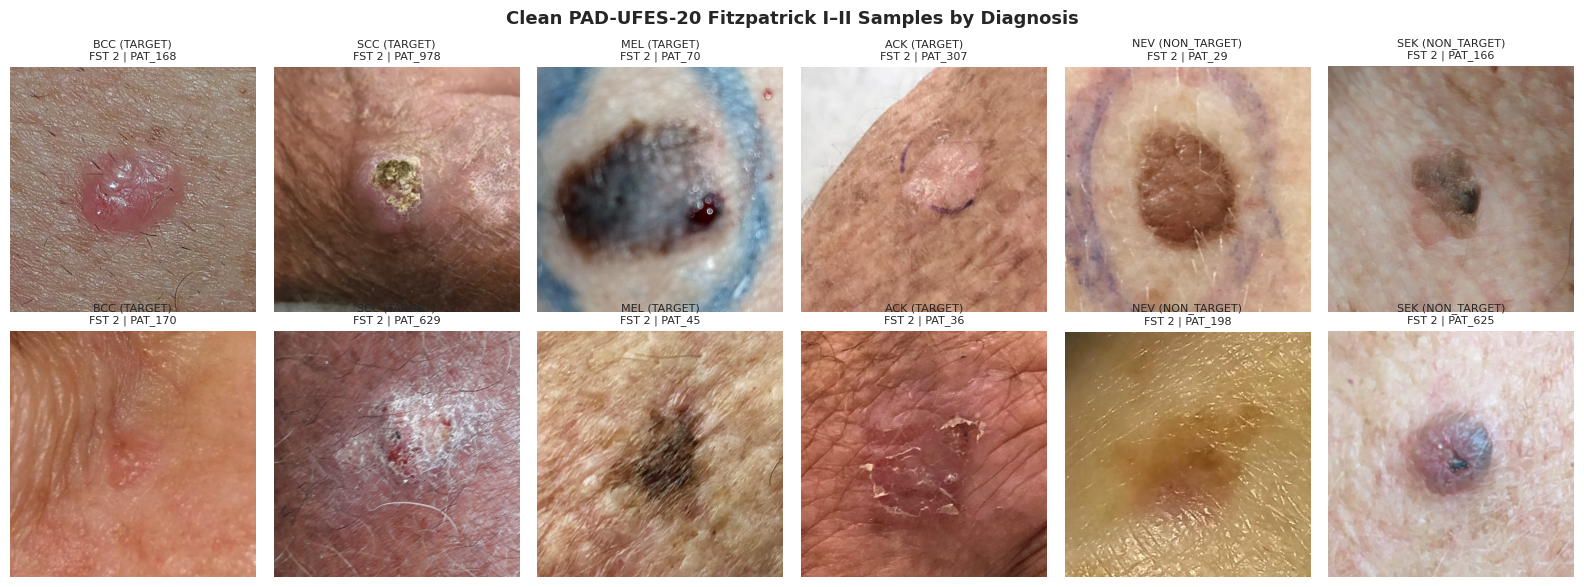

In [9]:
df_pad_clean = df_pad[~df_pad["exclude"]].copy()
df_pad_fst12_clean = df_pad_clean[df_pad_clean[fst_col].isin([1.0, 2.0])].copy()

print(f"Total Clean PAD-UFES-20 Images (All Skin Types): {len(df_pad_clean)} (Excluded: {df_pad['exclude'].sum()})")
print(f"Total Clean PAD-UFES-20 Images (FST I–II Only):  {len(df_pad_fst12_clean)}")

print("\n=== CLEAN FST I–II SUBSET DISTRIBUTION (AFTER DEDUPLICATION) ===")
clean_fst12_table = df_pad_fst12_clean.groupby(["label_group", "diagnostic"]).agg(
    images=("img_id", "count"),
    unique_lesions=("lesion_id", "nunique"),
    unique_patients=("patient_id", "nunique"),
    biopsied=("biopsed", lambda x: (x == True).sum())
).reset_index()
display(clean_fst12_table)

# Show two random examples for each diagnosis in the clean FST I–II subset.
diagnoses_order = ["BCC", "SCC", "MEL", "ACK", "NEV", "SEK"]
fig, axes = plt.subplots(2, 6, figsize=(16, 6))

for col_idx, diag in enumerate(diagnoses_order):
    subset = df_pad_fst12_clean[df_pad_fst12_clean["diagnostic"] == diag]
    samples = subset.sample(n=min(2, len(subset)), random_state=SEED)
    for row_idx, (_, s_row) in enumerate(samples.iterrows()):
        ax = axes[row_idx, col_idx]
        with Image.open(s_row["filepath"]) as im:
            ax.imshow(im)
        ax.set_title(f"{diag} ({s_row['label_group']})\nFST {int(s_row[fst_col])} | {s_row['patient_id']}", fontsize=8)
        ax.axis("off")

plt.suptitle("Clean PAD-UFES-20 Fitzpatrick I–II Samples by Diagnosis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "pad_ufes_fst12_sample_grid.png", dpi=150)
plt.show()

In [10]:
# Use the same column names in the later notebooks.
STANDARD_COLS = [
    "dataset_source",
    "image_id",
    "patient_id",
    "lesion_id",
    "filepath",
    "diagnostic",
    "label_group",
    "binary_label",
    "fitzpatrick_type",
    "biopsied",
    "age",
    "gender",
    "region",
    "width",
    "height",
    "aspect_ratio",
    "mean_brightness",
    "sharpness_laplacian",
    "md5_hash"
]

df_pad["dataset_source"] = "PAD_UFES_20"
df_pad["image_id"] = df_pad["img_id"]
df_pad["binary_label"] = (df_pad["label_group"] == "TARGET").astype(int)
df_pad["fitzpatrick_type"] = df_pad[fst_col]
df_pad["biopsied"] = df_pad["biopsed"]

# 1. Save the exclusion log.
df_excluded = df_pad[df_pad["exclude"]][
    ["dataset_source", "image_id", "patient_id", "lesion_id", "diagnostic", "label_group", "fitzpatrick_type", "md5_hash", "exclusion_reason", "filepath"]
].sort_values(["exclusion_reason", "md5_hash", "image_id"])

exclusion_log_path = MANIFEST_DIR / "pad_ufes_20_exclusion_log.csv"
df_excluded.to_csv(exclusion_log_path, index=False)
print(f"Saved Exclusion Log ({len(df_excluded)} rows) -> {exclusion_log_path}")

# 2. Save the full clean manifest for all Fitzpatrick types.
df_clean_all = df_pad[~df_pad["exclude"]][STANDARD_COLS].sort_values("image_id").reset_index(drop=True)
clean_all_path = MANIFEST_DIR / "pad_ufes_20_clean_all_fst.csv"
df_clean_all.to_csv(clean_all_path, index=False)
print(f"Saved Clean All-FST Manifest ({len(df_clean_all)} rows) -> {clean_all_path}")

# 3. Save the clean Fitzpatrick I–II baseline manifest.
df_clean_fst12 = df_clean_all[df_clean_all["fitzpatrick_type"].isin([1.0, 2.0])].reset_index(drop=True)
clean_fst12_path = MANIFEST_DIR / "pad_ufes_20_clean_fst12.csv"
df_clean_fst12.to_csv(clean_fst12_path, index=False)
print(f"Saved Clean FST I–II Manifest ({len(df_clean_fst12)} rows) -> {clean_fst12_path}")

Saved Exclusion Log (27 rows) -> /content/drive/MyDrive/SkinX/data/manifests/pad_ufes_20_exclusion_log.csv
Saved Clean All-FST Manifest (2271 rows) -> /content/drive/MyDrive/SkinX/data/manifests/pad_ufes_20_clean_all_fst.csv
Saved Clean FST I–II Manifest (1004 rows) -> /content/drive/MyDrive/SkinX/data/manifests/pad_ufes_20_clean_fst12.csv


In [11]:
import subprocess

RAW_MILK_DIR = PROJECT_ROOT / "data" / "raw_data" / "milk10k"
if not RAW_MILK_DIR.exists():
    raise FileNotFoundError(f"MILK10k folder not found: {RAW_MILK_DIR}")

print(f"Checking MILK10k directory: {RAW_MILK_DIR}")
existing_files = list(RAW_MILK_DIR.rglob("*"))
print(f"Files currently in RAW_MILK_DIR: {len(existing_files)}")

# ZIP archives are handled below; keep extracted files out of the raw-data folder.
csv_files = sorted(RAW_MILK_DIR.rglob("*.csv"))
zip_files = sorted(RAW_MILK_DIR.rglob("*.zip"))
if not csv_files and not zip_files:
    raise FileNotFoundError(
        "MILK10k metadata was not found. Download the official ISIC bundle "
        "and place it in RAW_MILK_DIR."
    )

# List the CSV files and folders in RAW_MILK_DIR.
print("\nContents of RAW_MILK_DIR:")
for item in sorted(RAW_MILK_DIR.iterdir()):
    kind = "[DIR] " if item.is_dir() else f"[FILE] ({item.stat().st_size / (1024*1024):.2f} MB)"
    print(f"  {kind} {item.name}")

csv_files = sorted(RAW_MILK_DIR.rglob("*.csv"))
print(f"\nFound {len(csv_files)} CSV file(s) in MILK10k:")
for c in csv_files:
    df_tmp = pd.read_csv(c, nrows=5)
    print(f"\n--- {c.relative_to(RAW_MILK_DIR)} ---")
    print("Columns:", df_tmp.columns.tolist())
    display(df_tmp.head(2))

Checking MILK10k directory: /content/drive/MyDrive/SkinX/data/raw_data/milk10k
Files currently in RAW_MILK_DIR: 10489

Contents of RAW_MILK_DIR:
  [FILE] (0.00 MB) attribution.txt
  [DIR]  images
  [DIR]  licenses
  [FILE] (2.03 MB) metadata.csv
  [DIR]  supplements

Found 4 CSV file(s) in MILK10k:

--- metadata.csv ---
Columns: ['isic_id', 'attribution', 'copyright_license', 'age_approx', 'anatom_site_general', 'anatom_site_special', 'concomitant_biopsy', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'diagnosis_4', 'diagnosis_confirm_type', 'image_manipulation', 'image_type', 'lesion_id', 'melanocytic', 'sex']


,isic_id,attribution,copyright_license,age_approx,anatom_site_general,anatom_site_special,concomitant_biopsy,diagnosis_1,diagnosis_2,diagnosis_3,diagnosis_4,diagnosis_confirm_type,image_manipulation,image_type,lesion_id,melanocytic,sex
0,ISIC_0051817,MILK study team,CC-BY-NC,70,upper extremity,NaN,True,Malignant,Malignant epidermal proliferations,"Squamous cell carcinoma, Invasive",NaN,histopathology,instrument only,dermoscopic,IL_1612768,NaN,male
1,ISIC_0073863,MILK study team,CC-BY-NC,5,NaN,NaN,True,Benign,Benign melanocytic proliferations,Nevus,"Nevus, Reed",histopathology,instrument only,dermoscopic,IL_2547802,True,female



--- supplements/training_gt.csv ---
Columns: ['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0,1,0,0,0,0,0,0,0,0,0
1,IL_0003176,0,1,0,0,0,0,0,0,0,0,0



--- supplements/training_input.csv ---
Columns: ['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']


,lesion_id,image_type,isic_id,attribution,copyright_license,image_manipulation,age_approx,sex,skin_tone_class,site,MONET_ulceration_crust,MONET_hair,MONET_vasculature_vessels,MONET_erythema,MONET_pigmented,MONET_gel_water_drop_fluid_dermoscopy_liquid,MONET_skin_markings_pen_ink_purple_pen
0,IL_0000652,clinical: close-up,ISIC_8149219,MILK study team,CC-BY-NC,altered,70,male,1,head_neck_face,0.166749,0.163601,0.002284,0.124315,0.719495,0.220399,0.237601
1,IL_0000652,dermoscopic,ISIC_4671410,MILK study team,CC-BY-NC,instrument only,70,male,1,head_neck_face,0.659859,0.156478,0.016397,0.032357,0.847014,0.138121,0.148776



--- supplements/training_supp.csv ---
Columns: ['isic_id', 'diagnosis_full', 'diagnosis_confirm_type', 'invasion_thickness_interval']


,isic_id,diagnosis_full,diagnosis_confirm_type,invasion_thickness_interval
0,ISIC_0051817,"Squamous cell carcinoma, Invasive",histopathology,NaN
1,ISIC_0073863,"Nevus, Reed",histopathology,NaN


In [12]:
# ==============================================================================
# Inspect the MILK10k dataset structure
# ==============================================================================
# Look under PROJECT_ROOT/data for the MILK10k folder.
milk_dirs = [
    p for p in (PROJECT_ROOT / "data").rglob("*")
    if p.is_dir() and "milk" in p.name.lower()
]
print("Found MILK10k directories on Drive:", [str(p) for p in milk_dirs])

RAW_MILK_DIR = PROJECT_ROOT / "data" / "raw_data" / "milk10k"
if not RAW_MILK_DIR.exists() and milk_dirs:
    RAW_MILK_DIR = milk_dirs[0]

print(f"\nUsing RAW_MILK_DIR: {RAW_MILK_DIR} (Exists: {RAW_MILK_DIR.exists()})")

# Check the files in RAW_MILK_DIR.
if RAW_MILK_DIR.exists():
    print("\nTop-level contents of RAW_MILK_DIR:")
    for item in sorted(RAW_MILK_DIR.iterdir()):
        kind = "[DIR] " if item.is_dir() else f"[FILE] ({item.stat().st_size / (1024*1024):.2f} MB)"
        print(f"  {kind} {item.name}")

# If the data are still archived, extract them under data/extracted/milk10k.
EXTRACTED_MILK_DIR = PROJECT_ROOT / "data" / "extracted" / "milk10k"
milk_zips = sorted(RAW_MILK_DIR.rglob("*.zip"))

if milk_zips:
    for zpath in milk_zips:
        dest = EXTRACTED_MILK_DIR / zpath.stem
        marker = dest / ".extraction_complete"
        if not marker.exists():
            dest.mkdir(parents=True, exist_ok=True)
            print(f"\nExtracting {zpath.name} to {dest} (raw archive stays untouched)...")
            with zipfile.ZipFile(zpath, "r") as zf:
                zf.extractall(dest)
            marker.touch()
        else:
            print(f"\nArchive {zpath.name} already extracted at {dest}")

# Look for CSV files and images in the raw and extracted folders.
search_roots = [d for d in [RAW_MILK_DIR, EXTRACTED_MILK_DIR] if d.exists()]
milk_csvs = []
milk_images = []
for root in search_roots:
    milk_csvs.extend(root.rglob("*.csv"))
    milk_images.extend(
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

milk_csvs = sorted(set(milk_csvs))
print(f"\nTotal CSV files found:   {len(milk_csvs)}")
for c in milk_csvs:
    print(f"  - {c}")
print(f"Total image files found: {len(milk_images)}")

Found MILK10k directories on Drive: ['/content/drive/MyDrive/SkinX/data/raw_data/milk10k']

Using RAW_MILK_DIR: /content/drive/MyDrive/SkinX/data/raw_data/milk10k (Exists: True)

Top-level contents of RAW_MILK_DIR:
  [FILE] (0.00 MB) attribution.txt
  [DIR]  images
  [DIR]  licenses
  [FILE] (2.03 MB) metadata.csv
  [DIR]  supplements

Total CSV files found:   4
  - /content/drive/MyDrive/SkinX/data/raw_data/milk10k/metadata.csv
  - /content/drive/MyDrive/SkinX/data/raw_data/milk10k/supplements/training_gt.csv
  - /content/drive/MyDrive/SkinX/data/raw_data/milk10k/supplements/training_input.csv
  - /content/drive/MyDrive/SkinX/data/raw_data/milk10k/supplements/training_supp.csv
Total image files found: 10480


In [13]:
# Load each CSV file found in MILK10k.
milk_dfs = {}
for csv_path in milk_csvs:
    df_temp = pd.read_csv(csv_path)
    milk_dfs[csv_path.name] = df_temp
    print("=" * 80)
    print(f"CSV FILE: {csv_path.name} | Shape: {df_temp.shape[0]} rows x {df_temp.shape[1]} cols")
    print("=" * 80)
    print("Columns:", df_temp.columns.tolist())
    display(df_temp.head(3))

    # Show counts for key categories such as modality, diagnosis and skin tone.
    for col in df_temp.columns:
        col_lower = col.lower()
        if any(k in col_lower for k in ["type", "modality", "diag", "dx", "cat", "label", "tone", "fst", "skin", "benign", "malignant"]):
            if df_temp[col].nunique(dropna=False) <= 30:
                print(f"\n--- Value Counts for '{col}' ---")
                display(df_temp[col].value_counts(dropna=False).rename("Count").to_frame())

CSV FILE: metadata.csv | Shape: 10480 rows x 17 cols
Columns: ['isic_id', 'attribution', 'copyright_license', 'age_approx', 'anatom_site_general', 'anatom_site_special', 'concomitant_biopsy', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'diagnosis_4', 'diagnosis_confirm_type', 'image_manipulation', 'image_type', 'lesion_id', 'melanocytic', 'sex']


,isic_id,attribution,copyright_license,age_approx,anatom_site_general,anatom_site_special,concomitant_biopsy,diagnosis_1,diagnosis_2,diagnosis_3,diagnosis_4,diagnosis_confirm_type,image_manipulation,image_type,lesion_id,melanocytic,sex
0,ISIC_0051817,MILK study team,CC-BY-NC,70.0,upper extremity,NaN,True,Malignant,Malignant epidermal proliferations,"Squamous cell carcinoma, Invasive",NaN,histopathology,instrument only,dermoscopic,IL_1612768,NaN,male
1,ISIC_0073863,MILK study team,CC-BY-NC,5.0,NaN,NaN,True,Benign,Benign melanocytic proliferations,Nevus,"Nevus, Reed",histopathology,instrument only,dermoscopic,IL_2547802,True,female
2,ISIC_0075884,MILK study team,CC-BY-NC,10.0,upper extremity,NaN,True,Benign,Benign melanocytic proliferations,Nevus,"Nevus, Acral",histopathology,instrument only,clinical: close-up,IL_9270970,True,female



--- Value Counts for 'diagnosis_1' ---


,Count
diagnosis_1,
Malignant,7268
Benign,2966
Indeterminate,246



--- Value Counts for 'diagnosis_2' ---


...

,Count
skin_tone_class,
3,6348
4,2132
2,1012
5,766
1,210
0,12


CSV FILE: training_supp.csv | Shape: 10480 rows x 4 cols
Columns: ['isic_id', 'diagnosis_full', 'diagnosis_confirm_type', 'invasion_thickness_interval']


,isic_id,diagnosis_full,diagnosis_confirm_type,invasion_thickness_interval
0,ISIC_0051817,"Squamous cell carcinoma, Invasive",histopathology,NaN
1,ISIC_0073863,"Nevus, Reed",histopathology,NaN
2,ISIC_0075884,"Nevus, Acral",histopathology,NaN



--- Value Counts for 'diagnosis_confirm_type' ---


,Count
diagnosis_confirm_type,
histopathology,10032
single contributor clinical assessment,448


In [14]:
# 1. Load the four CSV files in the official ISIC MILK10k release.
df_milk_meta = milk_dfs["metadata.csv"].copy()
df_milk_input = milk_dfs["training_input.csv"].copy()
df_milk_gt = milk_dfs["training_gt.csv"].copy()
df_milk_supp = milk_dfs["training_supp.csv"].copy()

# 2. Check row keys and one-hot diagnosis labels before joining the tables.
for table, keys in [
    (df_milk_meta, ["isic_id"]),
    (df_milk_input, ["isic_id"]),
    (df_milk_gt, ["lesion_id"]),
    (df_milk_supp, ["isic_id"]),
]:
    if table.duplicated(keys).any():
        raise ValueError(f"Duplicate keys in MILK10k metadata: {keys}")

DX_COLS = ["AKIEC", "BCC", "BEN_OTH", "BKL", "DF", "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"]
if not df_milk_gt[DX_COLS].sum(axis=1).eq(1).all():
    raise ValueError("Each MILK10k lesion must have exactly one one-hot diagnosis label.")
df_milk_gt["milk_dx"] = df_milk_gt[DX_COLS].idxmax(axis=1)

# 3. Skin tone is in training_input.csv; detailed diagnoses are in training_supp.csv.
# Join images by isic_id and group diagnoses by lesion_id.
df_milk = df_milk_meta.merge(
    df_milk_input[["isic_id", "lesion_id", "image_type", "skin_tone_class", "site"]],
    on=["isic_id", "lesion_id", "image_type"], how="left", validate="one_to_one"
)
df_milk = df_milk.merge(
    df_milk_gt[["lesion_id", "milk_dx"]],
    on="lesion_id", how="left", validate="many_to_one"
)
df_milk = df_milk.merge(
    df_milk_supp[["isic_id", "diagnosis_full", "diagnosis_confirm_type"]].rename(
        columns={"diagnosis_confirm_type": "supp_confirm_type"}
    ), on="isic_id", how="left", validate="one_to_one"
)

if df_milk[["skin_tone_class", "milk_dx"]].isna().any().any():
    raise ValueError("Some MILK10k rows lack skin tone or lesion diagnosis after merging.")

# Check whether the two diagnosis-confirmation fields agree.
meta_confirm = df_milk["diagnosis_confirm_type"].astype("string").str.strip().str.lower()
supp_confirm = df_milk["supp_confirm_type"].astype("string").str.strip().str.lower()
df_milk["confirmation_conflict"] = (
    meta_confirm.notna() & supp_confirm.notna() & meta_confirm.ne(supp_confirm).fillna(False)
)
df_milk["diagnosis_confirm_type"] = meta_confirm.fillna(supp_confirm)
df_milk["biopsied"] = df_milk["diagnosis_confirm_type"].eq("histopathology").astype("boolean")

# 4. Map diagnoses to TARGET and NON_TARGET conservatively; broad groups may include unsuitable subtypes.
# SCCKA includes keratoacanthoma; BKL and BEN_OTH are not automatically safe NON_TARGET labels.
df_milk["diagnosis_full"] = df_milk["diagnosis_full"].fillna(
    df_milk["diagnosis_4"]
).fillna(df_milk["diagnosis_3"])

def classify_milk(dx, diagnosis):
    name = str(diagnosis).strip().lower() if pd.notna(diagnosis) else ""
    if dx in {"BCC", "MEL", "AKIEC"}:
        return "TARGET", "IN_SCOPE_TARGET"
    if dx == "SCCKA":
        if "squamous cell carcinoma" in name:
            return "TARGET", "CONFIRMED_SCC_CATEGORY"
        return "EXCLUDE", "SCCKA_SUBTYPE_REQUIRES_REVIEW"
    if dx == "NV":
        return "NON_TARGET", "BENIGN_NEVUS_CATEGORY"
    if dx == "DF":
        return "NON_TARGET", "DERMATOFIBROMA_CATEGORY"
    if dx == "BKL":
        safe_names = ["seborrheic keratosis", "solar lentigo", "lichen planus-like keratosis", "lichenoid keratosis"]
        if any(term in name for term in safe_names):
            return "NON_TARGET", "SELECTED_BENIGN_KERATINOCYTIC_DIAGNOSIS"
        return "EXCLUDE", "BKL_SUBTYPE_REQUIRES_REVIEW"
    return "EXCLUDE", "CATEGORY_OUTSIDE_APPROVED_SKINX_SCOPE"

df_milk[["label_group", "selection_reason"]] = pd.DataFrame(
    [classify_milk(dx, diagnosis) for dx, diagnosis in zip(df_milk["milk_dx"], df_milk["diagnosis_full"])],
    index=df_milk.index
)
df_milk.loc[df_milk["confirmation_conflict"], ["label_group", "selection_reason"]] = [
    "EXCLUDE", "CONFLICTING_CONFIRMATION_METADATA"
]

# MILK10k tone runs from 0 (darkest) to 5 (lightest); it is not the Fitzpatrick scale.
df_milk["skin_tone_class"] = pd.to_numeric(df_milk["skin_tone_class"], errors="raise")
df_milk_closeup = df_milk[df_milk["image_type"] == "clinical: close-up"].copy()
print(f"Total merged MILK10k rows: {len(df_milk)}")
print(f"Clinical close-up images: {len(df_milk_closeup)} | Unique lesions: {df_milk_closeup['lesion_id'].nunique()}")
print("Patient IDs: not supplied by MILK10k (lesion IDs are not patient IDs).")
print(f"Diagnosis-confirmation disagreements: {df_milk_closeup['confirmation_conflict'].sum()}")

print("\n=== MILK10k CLINICAL CLOSE-UP: SKIN TONE vs. DIAGNOSIS ===")
display(pd.crosstab(df_milk_closeup["skin_tone_class"], df_milk_closeup["milk_dx"], margins=True))

print("\n=== LIGHT-APPEARING TONE 4–5: APPROVED AND REVIEW-NEEDED DIAGNOSES ===")
df_milk_light = df_milk_closeup[df_milk_closeup["skin_tone_class"].isin([4, 5])].copy()
display(df_milk_light.groupby(["label_group", "milk_dx", "selection_reason"], dropna=False).agg(
    images=("isic_id", "count"),
    unique_lesions=("lesion_id", "nunique"),
    histopathology_confirmed=("biopsied", lambda x: int(x.fillna(False).sum()))
).reset_index())

print("\nNOTE: MILK10k tone 4–5 means lighter visible skin, NOT Fitzpatrick I–II.")


Total merged MILK10k rows: 10480
Clinical close-up images: 5240 | Unique lesions: 5240
Patient IDs: not supplied by MILK10k (lesion IDs are not patient IDs).
Diagnosis-confirmation disagreements: 0

=== MILK10k CLINICAL CLOSE-UP: SKIN TONE vs. DIAGNOSIS ===


milk_dx,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC,All
skin_tone_class,,,,,,,,,,,,
0,0,1,0,0,0,3,0,0,2,0,0,6
1,19,19,2,24,4,2,1,16,16,1,1,105
2,21,77,11,59,9,5,3,121,185,5,10,506
3,202,1716,22,343,25,16,5,200,319,304,22,3174
4,46,496,6,94,9,10,0,90,172,135,8,1066
5,15,213,3,24,5,14,0,23,52,28,6,383
All,303,2522,44,544,52,50,9,450,746,473,47,5240



=== LIGHT-APPEARING TONE 4–5: APPROVED AND REVIEW-NEEDED DIAGNOSES ===


,label_group,milk_dx,selection_reason,images,unique_lesions,histopathology_confirmed
0,EXCLUDE,BEN_OTH,CATEGORY_OUTSIDE_APPROVED_SKINX_SCOPE,9,9,7
1,EXCLUDE,BKL,BKL_SUBTYPE_REQUIRES_REVIEW,24,24,24
2,EXCLUDE,INF,CATEGORY_OUTSIDE_APPROVED_SKINX_SCOPE,24,24,21
3,EXCLUDE,SCCKA,SCCKA_SUBTYPE_REQUIRES_REVIEW,49,49,49
4,EXCLUDE,VASC,CATEGORY_OUTSIDE_APPROVED_SKINX_SCOPE,14,14,14
5,NON_TARGET,BKL,SELECTED_BENIGN_KERATINOCYTIC_DIAGNOSIS,94,94,91
6,NON_TARGET,DF,DERMATOFIBROMA_CATEGORY,14,14,12
7,NON_TARGET,NV,BENIGN_NEVUS_CATEGORY,224,224,191
8,TARGET,AKIEC,IN_SCOPE_TARGET,61,61,61
9,TARGET,BCC,IN_SCOPE_TARGET,709,709,708



NOTE: MILK10k tone 4–5 means lighter visible skin, NOT Fitzpatrick I–II.


In [15]:
# 1. Match MILK10k image IDs to files and keep duplicate filenames for review.
milk_image_map = {}
for p in milk_images:
    if p.stem in milk_image_map and milk_image_map[p.stem] != str(p):
        raise ValueError(f"More than one image file has the same ISIC ID: {p.stem}")
    milk_image_map[p.stem] = str(p)

df_milk_closeup["filepath"] = df_milk_closeup["isic_id"].map(milk_image_map)
df_milk_closeup["file_exists"] = df_milk_closeup["filepath"].notna()
print(f"MILK10k clinical close-ups matched: {df_milk_closeup['file_exists'].sum()} / {len(df_milk_closeup)}")

# 2. Select approved NON_TARGET diagnoses in tone groups 4 and 5.
df_milk_non_target_light = df_milk_closeup[
    (df_milk_closeup["label_group"] == "NON_TARGET") &
    (df_milk_closeup["skin_tone_class"].isin([4, 5]))
].copy().reset_index(drop=True)

print(f"\nLight-tone 4–5 NON_TARGET candidates: {len(df_milk_non_target_light)}")
print(f"Unique lesions/cases: {df_milk_non_target_light['lesion_id'].nunique()}")
print("Unique patients: unavailable (MILK10k does not provide patient IDs).")
print("\n=== APPROVED NON_TARGET CATEGORY BREAKDOWN ===")
display(df_milk_non_target_light.groupby("milk_dx").agg(
    images=("isic_id", "count"),
    unique_lesions=("lesion_id", "nunique"),
    histopathology_confirmed=("biopsied", lambda x: int(x.fillna(False).sum()))
).reset_index().sort_values("images", ascending=False))


MILK10k clinical close-ups matched: 5240 / 5240

Light-tone 4–5 NON_TARGET candidates: 332
Unique lesions/cases: 332
Unique patients: unavailable (MILK10k does not provide patient IDs).

=== APPROVED NON_TARGET CATEGORY BREAKDOWN ===


,milk_dx,images,unique_lesions,histopathology_confirmed
2,NV,224,224,191
0,BKL,94,94,91
1,DF,14,14,12


In [16]:
milk_integrity_records = []

print("Verifying MILK10k light-tone NON_TARGET image integrity, dimensions, brightness, sharpness, and MD5 hashes...")
for idx, row in tqdm(df_milk_non_target_light.iterrows(), total=len(df_milk_non_target_light)):
    isic_id = row["isic_id"]
    fpath = row["filepath"]

    if pd.isna(fpath) or not os.path.exists(fpath):
        milk_integrity_records.append({
            "isic_id": isic_id, "is_valid": False, "error_reason": "MISSING_FILE",
            "width": np.nan, "height": np.nan, "aspect_ratio": np.nan,
            "mean_brightness": np.nan, "sharpness_laplacian": np.nan, "md5_hash": None
        })
        continue

    try:
        with open(fpath, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        with Image.open(fpath) as im:
            im.load()
            w, h = im.size
            gray = np.array(im.convert("L"), dtype=np.float32)

        b_val = float(gray.mean())
        gray_resized = cv2.resize(gray, (256, 256))
        s_val = float(cv2.Laplacian(gray_resized, cv2.CV_32F).var())

        milk_integrity_records.append({
            "isic_id": isic_id, "is_valid": True, "error_reason": None,
            "width": w, "height": h, "aspect_ratio": round(w / h, 3),
            "mean_brightness": round(b_val, 2), "sharpness_laplacian": round(s_val, 2),
            "md5_hash": file_hash
        })
    except (OSError, UnidentifiedImageError, ValueError) as e:
        milk_integrity_records.append({
            "isic_id": isic_id, "is_valid": False, "error_reason": f"CORRUPTED: {type(e).__name__}",
            "width": np.nan, "height": np.nan, "aspect_ratio": np.nan,
            "mean_brightness": np.nan, "sharpness_laplacian": np.nan, "md5_hash": None
        })

if not milk_integrity_records:
    raise ValueError("No approved light-tone MILK10k NON_TARGET images were found. Review the diagnosis counts first.")

df_milk_int = pd.DataFrame(milk_integrity_records)
df_milk_non_target_light = df_milk_non_target_light.drop(columns=df_milk_int.columns.drop("isic_id"), errors="ignore")
df_milk_non_target_light = df_milk_non_target_light.merge(df_milk_int, on="isic_id", how="left")

# Flag invalid files and duplicate hashes.
df_milk_non_target_light["exclude"] = ~df_milk_non_target_light["is_valid"]
df_milk_non_target_light["exclusion_reason"] = df_milk_non_target_light["error_reason"]

# Check for duplicate files within MILK10k.
valid_milk = df_milk_non_target_light[df_milk_non_target_light["is_valid"]]
dup_milk_hashes = valid_milk[valid_milk["md5_hash"].duplicated(keep=False)]["md5_hash"].unique()

for h in dup_milk_hashes:
    grp = df_milk_non_target_light[df_milk_non_target_light["md5_hash"] == h].sort_values("isic_id")
    if grp["milk_dx"].nunique() > 1:
        df_milk_non_target_light.loc[grp.index, "exclude"] = True
        df_milk_non_target_light.loc[grp.index, "exclusion_reason"] = "DUPLICATE_HASH_CONFLICTING_DIAGNOSIS"
    else:
        df_milk_non_target_light.loc[grp.index[1:], "exclude"] = True
        df_milk_non_target_light.loc[grp.index[1:], "exclusion_reason"] = "DUPLICATE_HASH_SAME_DIAGNOSIS"

# Check whether any MILK10k image duplicates a PAD-UFES-20 image.
pad_hashes = set(df_clean_all["md5_hash"].dropna())
cross_dup_mask = df_milk_non_target_light["md5_hash"].isin(pad_hashes) & (~df_milk_non_target_light["exclude"])
if cross_dup_mask.any():
    df_milk_non_target_light.loc[cross_dup_mask, "exclude"] = True
    df_milk_non_target_light.loc[cross_dup_mask, "exclusion_reason"] = "CROSS_DATASET_DUPLICATE_WITH_PAD_UFES"

df_milk_clean = df_milk_non_target_light[~df_milk_non_target_light["exclude"]].copy().reset_index(drop=True)

print(f"\nMILK10k Integrity & Deduplication Summary:")
print(f"  - Valid unique MILK10k NON_TARGET images: {len(df_milk_clean)}")
print(f"  - Excluded rows:                          {df_milk_non_target_light['exclude'].sum()}")
print("\n=== MILK10k CLEAN NON_TARGET DIMENSION & QUALITY SUMMARY ===")
display(df_milk_clean[["width", "height", "aspect_ratio", "mean_brightness", "sharpness_laplacian"]].describe().round(2))

Verifying MILK10k light-tone NON_TARGET image integrity, dimensions, brightness, sharpness, and MD5 hashes...


  0%|          | 0/332 [00:00<?, ?it/s]


MILK10k Integrity & Deduplication Summary:
  - Valid unique MILK10k NON_TARGET images: 332
  - Excluded rows:                          0

=== MILK10k CLEAN NON_TARGET DIMENSION & QUALITY SUMMARY ===


,width,height,aspect_ratio,mean_brightness,sharpness_laplacian
count,332.0,332.0,332.00,332.00,332.00
mean,600.0,450.0,1.33,163.09,649.10
std,0.0,0.0,0.00,20.66,775.82
min,600.0,450.0,1.33,40.14,6.45
25%,600.0,450.0,1.33,153.02,229.20
50%,600.0,450.0,1.33,164.69,419.92
75%,600.0,450.0,1.33,175.14,768.20
max,600.0,450.0,1.33,209.91,6029.14


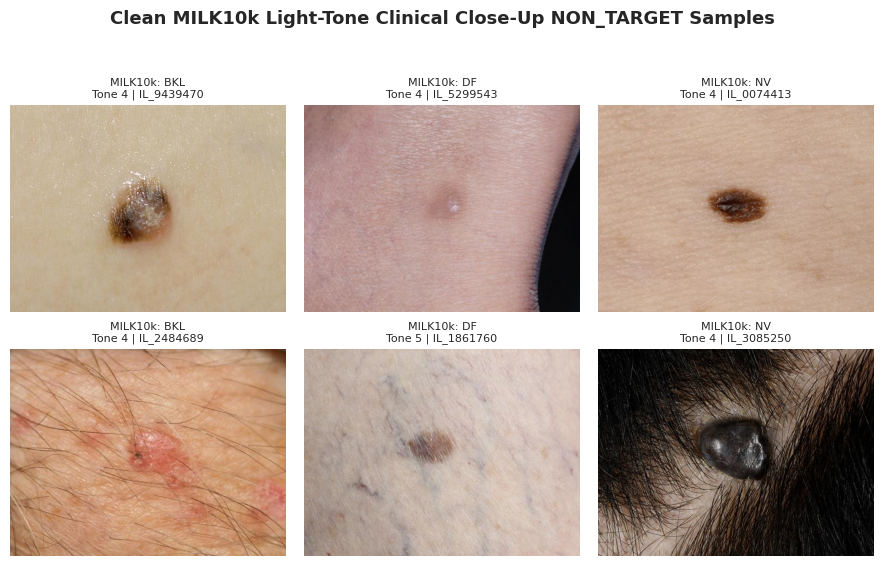

Saved clean MILK10k NON_TARGET manifest (332 rows) -> /content/drive/MyDrive/SkinX/data/manifests/milk10k_clean_light_tone_45_non_target.csv
Saved NON_TARGET image-integrity exclusions (0 rows) -> /content/drive/MyDrive/SkinX/data/manifests/milk10k_exclusion_log.csv

=== PRELIMINARY LIGHT-SKIN BASELINE (PAD FST I–II + MILK TONE 4–5 NON_TARGET) ===


/tmp/ipykernel_1124/3047408618.py:60: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_combined_preview = pd.concat([df_clean_fst12, df_milk_export], ignore_index=True)


,label_group,dataset_source,images,unique_lesions,histopathology_pct,mean_width,mean_height
0,NON_TARGET,MILK10K,332,332,88.6,600.000000,450.000000
1,NON_TARGET,PAD_UFES_20,63,51,60.3,787.761905,787.825397
2,TARGET,PAD_UFES_20,941,743,92.9,913.742827,913.814028



NOTE: MILK10k does not supply patient IDs; use lesion-level grouping and document this limitation.


In [17]:
# 1. Display a sample of the clean, light-tone MILK10k NON_TARGET images.
milk_diags = sorted(df_milk_clean["milk_dx"].unique())
if not milk_diags:
    raise ValueError("No clean MILK10k NON_TARGET images remain after validation.")
fig, axes = plt.subplots(2, len(milk_diags), figsize=(3 * len(milk_diags), 6), squeeze=False)
for col_idx, diag in enumerate(milk_diags):
    sub = df_milk_clean[df_milk_clean["milk_dx"] == diag]
    samps = sub.sample(n=min(2, len(sub)), random_state=SEED)
    for row_idx, (_, s_row) in enumerate(samps.iterrows()):
        ax = axes[row_idx, col_idx]
        with Image.open(s_row["filepath"]) as im:
            ax.imshow(im)
        ax.set_title(f"MILK10k: {diag}\nTone {int(s_row['skin_tone_class'])} | {s_row['lesion_id']}", fontsize=8)
        ax.axis("off")
    for row_idx in range(len(samps), 2):
        axes[row_idx, col_idx].axis("off")
plt.suptitle("Clean MILK10k Light-Tone Clinical Close-Up NON_TARGET Samples", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(REPORT_DIR / "milk10k_non_target_sample_grid.png", dpi=150)
plt.show()

# 2. Keep the PAD-UFES columns and add the MILK10k-specific fields.
MILK_EXTRA_COLS = [
    "group_id", "grouping_level", "skin_tone_class", "skin_tone_scale",
    "diagnosis_full", "diagnosis_confirm_type", "concomitant_biopsy"
]

def prepare_milk_manifest(frame, binary_label):
    result = frame.copy()
    result["dataset_source"] = "MILK10K"
    result["image_id"] = result["isic_id"] + ".jpg"
    # MILK10k has lesion IDs but no reliable patient IDs.
    result["patient_id"] = pd.NA
    result["group_id"] = "MILK_" + result["lesion_id"].astype(str)
    result["grouping_level"] = "lesion (patient IDs unavailable)"
    result["lesion_id"] = result["group_id"]
    result["diagnostic"] = result["milk_dx"]
    result["binary_label"] = binary_label
    result["fitzpatrick_type"] = pd.NA  # The MILK10k tone scale is different from Fitzpatrick.
    result["skin_tone_scale"] = "MILK10k: 0 very dark to 5 very light"
    # Here, "biopsied" means the diagnosis was confirmed by histopathology.
    result["biopsied"] = result["diagnosis_confirm_type"].eq("histopathology").astype("boolean")
    result["age"] = result["age_approx"]
    result["gender"] = result["sex"].str.upper()
    result["region"] = result["site"].fillna(result["anatom_site_general"]).str.upper().fillna("UNKNOWN")
    return result[STANDARD_COLS + MILK_EXTRA_COLS].sort_values("image_id").reset_index(drop=True)

# 3. Save the reviewed NON_TARGET candidates and keep their exclusion log.
df_milk_export = prepare_milk_manifest(df_milk_clean, binary_label=0)
milk_manifest_path = MANIFEST_DIR / "milk10k_clean_light_tone_45_non_target.csv"
df_milk_export.to_csv(milk_manifest_path, index=False)
print(f"Saved clean MILK10k NON_TARGET manifest ({len(df_milk_export)} rows) -> {milk_manifest_path}")

df_milk_excluded = df_milk_non_target_light[df_milk_non_target_light["exclude"]].copy()
milk_excl_path = MANIFEST_DIR / "milk10k_exclusion_log.csv"
df_milk_excluded.to_csv(milk_excl_path, index=False)
print(f"Saved NON_TARGET image-integrity exclusions ({len(df_milk_excluded)} rows) -> {milk_excl_path}")

# 4. Check source and class counts; TARGET cases are added in the next section.
df_combined_preview = pd.concat([df_clean_fst12, df_milk_export], ignore_index=True)
print("\n=== PRELIMINARY LIGHT-SKIN BASELINE (PAD FST I–II + MILK TONE 4–5 NON_TARGET) ===")
display(df_combined_preview.groupby(["label_group", "dataset_source"]).agg(
    images=("image_id", "count"),
    unique_lesions=("lesion_id", "nunique"),
    histopathology_pct=("biopsied", lambda x: round(x.fillna(False).mean() * 100, 1)),
    mean_width=("width", "mean"),
    mean_height=("height", "mean")
).reset_index())
print("\nNOTE: MILK10k does not supply patient IDs; use lesion-level grouping and document this limitation.")


In [18]:
# ==============================================================================
# Extract MILK10k TARGET cases: light-tone 4–5 clinical close-ups
# ==============================================================================
df_milk_target_light = df_milk_closeup[
    (df_milk_closeup["label_group"] == "TARGET") &
    (df_milk_closeup["skin_tone_class"].isin([4, 5]))
].copy().reset_index(drop=True)

print(f"Light-tone 4–5 MILK10k TARGET candidates: {len(df_milk_target_light)}")
print(f"Unique lesions/cases: {df_milk_target_light['lesion_id'].nunique()}")
print("Unique patients: unavailable (patient IDs are not supplied).")
print("\n=== MILK10k LIGHT-TONE TARGET BREAKDOWN ===")
display(df_milk_target_light.groupby("milk_dx").agg(
    images=("isic_id", "count"),
    unique_lesions=("lesion_id", "nunique"),
    histopathology_confirmed=("biopsied", lambda x: int(x.fillna(False).sum()))
).reset_index())

# Check image integrity and exact duplicates as for NON_TARGET images.
milk_target_integrity = []
print("\nVerifying MILK10k TARGET image integrity and MD5 hashes...")
for idx, row in tqdm(df_milk_target_light.iterrows(), total=len(df_milk_target_light)):
    isic_id, fpath = row["isic_id"], row["filepath"]
    if pd.isna(fpath) or not os.path.exists(fpath):
        milk_target_integrity.append({
            "isic_id": isic_id, "is_valid": False, "error_reason": "MISSING_FILE",
            "width": np.nan, "height": np.nan, "aspect_ratio": np.nan,
            "mean_brightness": np.nan, "sharpness_laplacian": np.nan, "md5_hash": None
        })
        continue
    try:
        with open(fpath, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        with Image.open(fpath) as im:
            im.load()
            w, h = im.size
            gray = np.array(im.convert("L"), dtype=np.float32)
        b_val = float(gray.mean())
        s_val = float(cv2.Laplacian(cv2.resize(gray, (256, 256)), cv2.CV_32F).var())
        milk_target_integrity.append({
            "isic_id": isic_id, "is_valid": True, "error_reason": None,
            "width": w, "height": h, "aspect_ratio": round(w / h, 3),
            "mean_brightness": round(b_val, 2), "sharpness_laplacian": round(s_val, 2),
            "md5_hash": file_hash
        })
    except (OSError, UnidentifiedImageError, ValueError) as e:
        milk_target_integrity.append({
            "isic_id": isic_id, "is_valid": False,
            "error_reason": f"CORRUPTED: {type(e).__name__}",
            "width": np.nan, "height": np.nan, "aspect_ratio": np.nan,
            "mean_brightness": np.nan, "sharpness_laplacian": np.nan, "md5_hash": None
        })

if not milk_target_integrity:
    raise ValueError("No approved MILK10k light-tone TARGET images were found.")
df_mt_int = pd.DataFrame(milk_target_integrity)
df_milk_target_light = df_milk_target_light.merge(df_mt_int, on="isic_id", how="left", validate="one_to_one")
df_milk_target_light["exclude"] = ~df_milk_target_light["is_valid"]
df_milk_target_light["exclusion_reason"] = df_milk_target_light["error_reason"]

valid_mt = df_milk_target_light[df_milk_target_light["is_valid"]]
for h in valid_mt.loc[valid_mt["md5_hash"].duplicated(keep=False), "md5_hash"].unique():
    grp = df_milk_target_light[df_milk_target_light["md5_hash"] == h].sort_values("isic_id")
    if grp["milk_dx"].nunique() > 1:
        df_milk_target_light.loc[grp.index, "exclude"] = True
        df_milk_target_light.loc[grp.index, "exclusion_reason"] = "DUPLICATE_HASH_CONFLICTING_DIAGNOSIS"
    else:
        df_milk_target_light.loc[grp.index[1:], "exclude"] = True
        df_milk_target_light.loc[grp.index[1:], "exclusion_reason"] = "DUPLICATE_HASH_SAME_DIAGNOSIS"

# Exclude images that duplicate PAD-UFES-20 or accepted MILK10k NON_TARGET files.
existing_hashes = set(df_clean_all["md5_hash"].dropna())
overlap_pad = df_milk_target_light["md5_hash"].isin(existing_hashes) & (~df_milk_target_light["exclude"])
df_milk_target_light.loc[overlap_pad, ["exclude", "exclusion_reason"]] = [True, "CROSS_DATASET_DUPLICATE_WITH_PAD"]

# An exact duplicate with different labels is a label conflict, not a routine duplicate.
non_target_hashes = set(df_milk_clean["md5_hash"].dropna())
conflicting_hashes = set(df_milk_target_light["md5_hash"].dropna()).intersection(non_target_hashes)
if conflicting_hashes:
    raise ValueError(
        f"Found {len(conflicting_hashes)} exact duplicate hash(es) across MILK TARGET/NON_TARGET. "
        "Review their diagnoses before exporting a combined dataset."
    )

df_milk_target_clean = df_milk_target_light[~df_milk_target_light["exclude"]].copy().reset_index(drop=True)
df_milk_target_export = prepare_milk_manifest(df_milk_target_clean, binary_label=1)
milk_target_manifest_path = MANIFEST_DIR / "milk10k_clean_light_tone_45_target.csv"
df_milk_target_export.to_csv(milk_target_manifest_path, index=False)
print(f"Saved clean MILK10k TARGET manifest ({len(df_milk_target_export)} rows) -> {milk_target_manifest_path}")

# Save an audit of all light-tone MILK10k images, including uncertain diagnoses.
light_audit = df_milk_closeup[df_milk_closeup["skin_tone_class"].isin([4, 5])][
    ["isic_id", "lesion_id", "skin_tone_class", "milk_dx", "diagnosis_full", "label_group", "selection_reason"]
].copy()
selected_ids = set(df_milk_export["image_id"].str.removesuffix(".jpg")).union(
    set(df_milk_target_export["image_id"].str.removesuffix(".jpg"))
)
light_audit["kept_in_manifest"] = light_audit["isic_id"].isin(selected_ids)
excluded_checks = pd.concat([
    df_milk_non_target_light[["isic_id", "exclusion_reason"]],
    df_milk_target_light[["isic_id", "exclusion_reason"]]
], ignore_index=True)
light_audit = light_audit.merge(excluded_checks, on="isic_id", how="left", validate="one_to_one")
light_audit["exclusion_reason"] = light_audit["exclusion_reason"].fillna(
    light_audit["selection_reason"].where(~light_audit["kept_in_manifest"])
)
audit_path = MANIFEST_DIR / "milk10k_light_tone_45_selection_audit.csv"
light_audit.to_csv(audit_path, index=False)
print(f"Saved MILK10k selection and exclusion audit ({len(light_audit)} rows) -> {audit_path}")

# ==============================================================================
# Build the combined light-skin research manifest
# ==============================================================================
# PAD-UFES-20 uses recorded FST I–II; MILK10k uses visual tone groups 4–5.
df_pad_for_union = df_clean_fst12.copy()
df_pad_for_union["group_id"] = "PAD_" + df_pad_for_union["patient_id"].astype(str)
df_pad_for_union["grouping_level"] = "patient"
df_pad_for_union["skin_tone_class"] = pd.NA
df_pad_for_union["skin_tone_scale"] = pd.NA
df_pad_for_union["diagnosis_full"] = df_pad_for_union["diagnostic"]
df_pad_for_union["diagnosis_confirm_type"] = pd.NA
df_pad_for_union["concomitant_biopsy"] = pd.NA

df_final_unified_light = pd.concat([
    df_pad_for_union,
    df_milk_export,
    df_milk_target_export
], ignore_index=True)

if df_final_unified_light["image_id"].duplicated().any():
    raise ValueError("Duplicate image IDs in combined manifest.")
if not df_final_unified_light["label_group"].isin(["TARGET", "NON_TARGET"]).all():
    raise ValueError("Combined manifest includes unapproved diagnosis labels.")
if not df_final_unified_light["group_id"].notna().all():
    raise ValueError("Some records have no grouping identifier.")

unified_path = MANIFEST_DIR / "skinX_unified_clean_light_skin_candidates.csv"
df_final_unified_light.to_csv(unified_path, index=False)
print(f"\nSaved combined light-skin candidate manifest ({len(df_final_unified_light)} rows) -> {unified_path}")
print("IMPORTANT: MILK tone 4–5 is NOT equivalent to Fitzpatrick I–II, and MILK group IDs are lesion-level only.")
print("The combined file is a candidate dataset for Notebook 02, not a patient-independent split.")
print("Do not use previously saved '*fst12*' MILK manifests; those used the wrong MILK tone direction.")

print("\n=== FINAL SOURCE / BINARY CLASS COMPOSITION ===")
display(df_final_unified_light.groupby(["label_group", "dataset_source"]).agg(
    total_images=("image_id", "count"),
    unique_lesions=("lesion_id", "nunique"),
    unique_groups=("group_id", "nunique"),
    histopathology_pct=("biopsied", lambda x: round(x.fillna(False).mean() * 100, 1))
).reset_index())
print("\n=== FINAL BINARY CLASS BALANCE ===")
display(df_final_unified_light.groupby("label_group").agg(
    total_images=("image_id", "count"),
    unique_lesions=("lesion_id", "nunique")
))


Light-tone 4–5 MILK10k TARGET candidates: 997
Unique lesions/cases: 997
Unique patients: unavailable (patient IDs are not supplied).

=== MILK10k LIGHT-TONE TARGET BREAKDOWN ===


,milk_dx,images,unique_lesions,histopathology_confirmed
0,AKIEC,61,61,61
1,BCC,709,709,708
2,MEL,113,113,113
3,SCCKA,114,114,114



Verifying MILK10k TARGET image integrity and MD5 hashes...


  0%|          | 0/997 [00:00<?, ?it/s]

Saved clean MILK10k TARGET manifest (997 rows) -> /content/drive/MyDrive/SkinX/data/manifests/milk10k_clean_light_tone_45_target.csv
Saved MILK10k selection and exclusion audit (1449 rows) -> /content/drive/MyDrive/SkinX/data/manifests/milk10k_light_tone_45_selection_audit.csv

Saved combined light-skin candidate manifest (2333 rows) -> /content/drive/MyDrive/SkinX/data/manifests/skinX_unified_clean_light_skin_candidates.csv
IMPORTANT: MILK tone 4–5 is NOT equivalent to Fitzpatrick I–II, and MILK group IDs are lesion-level only.
The combined file is a candidate dataset for Notebook 02, not a patient-independent split.
Do not use previously saved '*fst12*' MILK manifests; those used the wrong MILK tone direction.

=== FINAL SOURCE / BINARY CLASS COMPOSITION ===


/tmp/ipykernel_1124/3420872228.py:124: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_final_unified_light = pd.concat([


,label_group,dataset_source,total_images,unique_lesions,unique_groups,histopathology_pct
0,NON_TARGET,MILK10K,332,332,332,88.6
1,NON_TARGET,PAD_UFES_20,63,51,48,60.3
2,TARGET,MILK10K,997,997,997,99.9
3,TARGET,PAD_UFES_20,941,743,512,92.9



=== FINAL BINARY CLASS BALANCE ===


,total_images,unique_lesions
label_group,,
NON_TARGET,395,383
TARGET,1938,1740


In [19]:

# ============================================================
# Validate and version the final dataset
# ============================================================

import shutil

# Load the final CSV from the previous step.
manifest_path = MANIFEST_DIR / "skinX_unified_clean_light_skin_candidates.csv"

df_check = pd.read_csv(manifest_path)

print("=== FINAL DATASET VALIDATION ===")

# 1. Check that the required columns are present.
required_cols = [
    "image_id",
    "filepath",
    "dataset_source",
    "diagnostic",
    "label_group",
    "binary_label",
    "group_id",
    "md5_hash",
    "fitzpatrick_type",
    "skin_tone_class"
]

missing_cols = set(required_cols) - set(df_check.columns)
assert not missing_cols, f"Missing columns: {missing_cols}"

# 2. Check the binary labels.
assert df_check["label_group"].isin(
    ["TARGET", "NON_TARGET"]
).all(), "Unknown classification labels found"

expected_labels = df_check["label_group"].map({
    "TARGET": 1,
    "NON_TARGET": 0
})

assert df_check["binary_label"].equals(
    expected_labels
), "Binary labels do not match TARGET/NON_TARGET"

# 3. Check IDs, file paths and group assignments.
assert df_check["image_id"].notna().all(), "Missing image IDs"
assert df_check["image_id"].is_unique, "Duplicate image IDs"
assert df_check["group_id"].notna().all(), "Missing group IDs"
assert df_check["filepath"].notna().all(), "Missing image paths"

# 4. Check for exact image duplicates.
assert df_check["md5_hash"].notna().all(), "Missing image hashes"
assert df_check["md5_hash"].is_unique, "Duplicate image hashes"

# 5. Confirm that the selected image files exist.
missing_files = [
    path for path in df_check["filepath"]
    if not Path(path).is_file()
]

assert not missing_files, (
    f"{len(missing_files)} image files could not be found"
)

# 6. Check the skin-selection rules.
pad = df_check[df_check["dataset_source"] == "PAD_UFES_20"]
milk = df_check[df_check["dataset_source"] == "MILK10K"]

assert len(pad) + len(milk) == len(df_check), "Unexpected dataset source"

assert pad["fitzpatrick_type"].isin([1, 2]).all(), (
    "PAD contains images outside FST I-II"
)

assert milk["skin_tone_class"].isin([4, 5]).all(), (
    "MILK contains images outside tone 4-5"
)

assert milk["fitzpatrick_type"].isna().all(), (
    "MILK skin tone was incorrectly stored as Fitzpatrick"
)

# 7. Summarize the final dataset.
print("\nDataset composition:")
display(pd.crosstab(
    df_check["dataset_source"],
    df_check["label_group"],
    margins=True
))

# 8. Save version 1 without overwriting an existing file.
version_path = MANIFEST_DIR / "skinX_unified_clean_light_skin_v1.csv"

if version_path.exists():
    assert version_path.read_bytes() == manifest_path.read_bytes(), (
        "Version 1 already exists with different data. "
        "Review the changes and create version 2 instead."
    )
else:
    shutil.copy2(manifest_path, version_path)

print("\nAll dataset validation checks passed.")
print("Total validated images:", len(df_check))
print("Frozen dataset:", version_path)


=== FINAL DATASET VALIDATION ===

Dataset composition:


label_group,NON_TARGET,TARGET,All
dataset_source,,,
MILK10K,332,997,1329
PAD_UFES_20,63,941,1004
All,395,1938,2333



All dataset validation checks passed.
Total validated images: 2333
Frozen dataset: /content/drive/MyDrive/SkinX/data/manifests/skinX_unified_clean_light_skin_v1.csv
